In [1]:
#Here we are setting up the Environment

!pip install pandas numpy scikit-learn torch transformers accelerate matplotlib seaborn

In [2]:
# Here we are importing all the required libraries

import pandas as pd
import numpy as np

import torch

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from torch.utils.data import Dataset

from transformers import (
    DistilBertTokenizer,
    DistilBertForSequenceClassification,
    Trainer,
    TrainingArguments
)

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Here it checks whether the device is having the NVDIA GPU or not.
# In my case the device doesnot contain NVDIA GPU so the training will take longer


print("PyTorch version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU is available")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available")
    print("Training will use CPU")

PyTorch version: 2.11.0+cu130
GPU is available
GPU: Tesla T4


In [4]:
#Read the CSV file

file_name = "/content/phishing.csv"

df = pd.read_csv(file_name)

# to display the no.of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (11054, 32)


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# to display the first 5 rows of the dataset
df.head()

,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
0,0,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
1,1,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
2,2,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
3,3,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1
4,4,-1,0,-1,1,-1,-1,1,1,-1,...,1,1,1,1,1,-1,1,-1,-1,1


In [7]:
# To display the column information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11054 entries, 0 to 11053
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Index                11054 non-null  int64
 1   UsingIP              11054 non-null  int64
 2   LongURL              11054 non-null  int64
 3   ShortURL             11054 non-null  int64
 4   Symbol@              11054 non-null  int64
 5   Redirecting//        11054 non-null  int64
 6   PrefixSuffix-        11054 non-null  int64
 7   SubDomains           11054 non-null  int64
 8   HTTPS                11054 non-null  int64
 9   DomainRegLen         11054 non-null  int64
 10  Favicon              11054 non-null  int64
 11  NonStdPort           11054 non-null  int64
 12  HTTPSDomainURL       11054 non-null  int64
 13  RequestURL           11054 non-null  int64
 14  AnchorURL            11054 non-null  int64
 15  LinksInScriptTags    11054 non-null  int64
 16  ServerFormHandler    1

In [8]:
#This displays all columns in the dataset. As our target is class which contains 1,-1
print(df.columns.tolist())

['Index', 'UsingIP', 'LongURL', 'ShortURL', 'Symbol@', 'Redirecting//', 'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'Favicon', 'NonStdPort', 'HTTPSDomainURL', 'RequestURL', 'AnchorURL', 'LinksInScriptTags', 'ServerFormHandler', 'InfoEmail', 'AbnormalURL', 'WebsiteForwarding', 'StatusBarCust', 'DisableRightClick', 'UsingPopupWindow', 'IframeRedirection', 'AgeofDomain', 'DNSRecording', 'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'LinksPointingToPage', 'StatsReport', 'class']


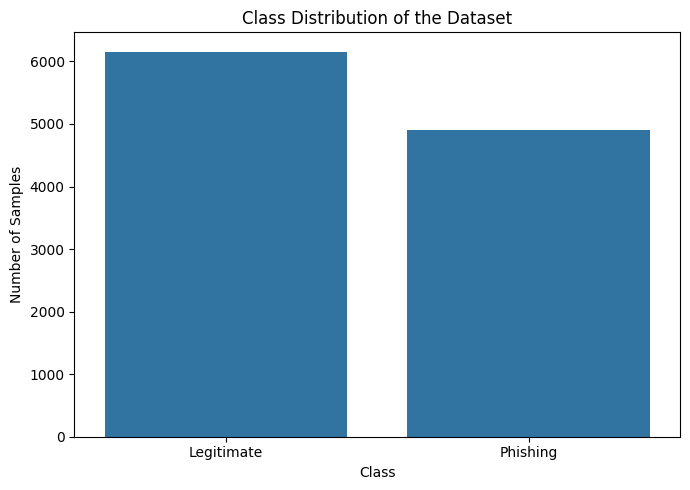

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

class_counts = df["class"].value_counts()

sns.barplot(
    x=["Legitimate", "Phishing"],
    y=[class_counts.get(1, 0), class_counts.get(-1, 0)]
)

plt.title("Class Distribution of the Dataset")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

In [10]:
#Check Missing Values
missing_values = df.isnull().sum()

print(missing_values)

Index                  0
UsingIP                0
LongURL                0
ShortURL               0
Symbol@                0
Redirecting//          0
PrefixSuffix-          0
SubDomains             0
HTTPS                  0
DomainRegLen           0
Favicon                0
NonStdPort             0
HTTPSDomainURL         0
RequestURL             0
AnchorURL              0
LinksInScriptTags      0
ServerFormHandler      0
InfoEmail              0
AbnormalURL            0
WebsiteForwarding      0
StatusBarCust          0
DisableRightClick      0
UsingPopupWindow       0
IframeRedirection      0
AgeofDomain            0
DNSRecording           0
WebsiteTraffic         0
PageRank               0
GoogleIndex            0
LinksPointingToPage    0
StatsReport            0
class                  0
dtype: int64


In [11]:
#It does not represent a phishing characteristic.
#If we leave it in the model, the model could learn meaningless patterns
df = df.drop(columns=["Index"])

print("Index column removed")
print("New shape:", df.shape)

Index column removed
New shape: (11054, 31)


In [12]:
#DistilBERT can only understand 2 numerical classes.
#   0 = Legitimate , 1 = Phishing
df["label"] = df["class"].map({
    1: 0,
    -1: 1
})

print(df[["class", "label"]].head(10))

   class  label
0     -1      1
1     -1      1
2     -1      1
3      1      0
4      1      0
5     -1      1
6     -1      1
7      1      0
8     -1      1
9      1      0


In [13]:
#This confirms that the conversion was successful.
print("Label distribution:")
print(df["label"].value_counts())

Label distribution:
label
0    6157
1    4897
Name: count, dtype: int64


In [14]:
#These are the 30 phishing-related features that we will use as the input.
feature_columns = [
    "UsingIP",
    "LongURL",
    "ShortURL",
    "Symbol@",
    "Redirecting//",
    "PrefixSuffix-",
    "SubDomains",
    "HTTPS",
    "DomainRegLen",
    "Favicon",
    "NonStdPort",
    "HTTPSDomainURL",
    "RequestURL",
    "AnchorURL",
    "LinksInScriptTags",
    "ServerFormHandler",
    "InfoEmail",
    "AbnormalURL",
    "WebsiteForwarding",
    "StatusBarCust",
    "DisableRightClick",
    "UsingPopupWindow",
    "IframeRedirection",
    "AgeofDomain",
    "DNSRecording",
    "WebsiteTraffic",
    "PageRank",
    "GoogleIndex",
    "LinksPointingToPage",
    "StatsReport"
]

In [15]:
#It confirms that all 30 features actually exist in the CSV.
missing_columns = [
    column for column in feature_columns
    if column not in df.columns
]

if len(missing_columns) == 0:
    print("All feature columns are available")
else:
    print("Missing columns:")
    print(missing_columns)

All feature columns are available


In [16]:
# we are converting one row into something like:
# UsingIP=1 LongURL=1 ShortURL=-1 HTTPS=1 PageRank=1 ...

def create_feature_text(row):

    text = ""

    for feature in feature_columns:

        feature_name = feature

        feature_name = feature_name.replace("@", "At")
        feature_name = feature_name.replace("/", "")
        feature_name = feature_name.replace("-", "Minus")

        text += f"{feature_name}={row[feature]} "

    return text.strip()

In [17]:
# creating a column named text
df["text"] = df.apply(
    create_feature_text,
    axis=1
)

print("Structured text created successfully")

Structured text created successfully


In [18]:
#This displays the structured text representation of the first website
print(df["text"].iloc[0])

UsingIP=1 LongURL=1 ShortURL=1 SymbolAt=1 Redirecting=1 PrefixSuffixMinus=-1 SubDomains=0 HTTPS=1 DomainRegLen=-1 Favicon=1 NonStdPort=1 HTTPSDomainURL=-1 RequestURL=1 AnchorURL=0 LinksInScriptTags=-1 ServerFormHandler=-1 InfoEmail=1 AbnormalURL=1 WebsiteForwarding=0 StatusBarCust=1 DisableRightClick=1 UsingPopupWindow=1 IframeRedirection=1 AgeofDomain=-1 DNSRecording=-1 WebsiteTraffic=0 PageRank=-1 GoogleIndex=1 LinksPointingToPage=1 StatsReport=1


In [19]:
# this is to show the text and label of the first 5 data
df[["text", "label"]].head()

,text,label
0,UsingIP=1 LongURL=1 ShortURL=1 SymbolAt=1 Redi...,1
1,UsingIP=1 LongURL=0 ShortURL=1 SymbolAt=1 Redi...,1
2,UsingIP=1 LongURL=0 ShortURL=1 SymbolAt=1 Redi...,1
3,UsingIP=1 LongURL=0 ShortURL=-1 SymbolAt=1 Red...,0
4,UsingIP=-1 LongURL=0 ShortURL=-1 SymbolAt=1 Re...,0


In [20]:
# we seperated text and label because the model needs:
#   Input → text , Output → label

texts = df["text"].values
labels = df["label"].values

print("Number of input samples:", len(texts))
print("Number of labels:", len(labels))

Number of input samples: 11054
Number of labels: 11054


In [21]:
#We first reserve 20% of the data for validation and testing and the remaining 80% will be used for training
X_train, X_temp, y_train, y_temp = train_test_split(
    texts,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

In [22]:
#The remaining 20% is divided equally:
#10% → Validation , 10% → Testing

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [23]:
#Verify Split

print("Training samples   :", len(X_train))
print("Validation samples :", len(X_val))
print("Testing samples    :", len(X_test))

Training samples   : 8843
Validation samples : 1105
Testing samples    : 1106


In [24]:
#The tokenizer converts our structured text into numerical tokens.
tokenizer = DistilBertTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

print("DistilBERT tokenizer loaded successfully")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

DistilBERT tokenizer loaded successfully


In [25]:
'''
PyTorch needs the data in a special format.

This class converts every sample into:

input_ids
attention_mask
labels

max_length=128 means each input is limited to 128 tokens.
'''

class PhishingDataset(Dataset):

    def __init__(
        self,
        texts,
        labels,
        tokenizer,
        max_length=128
    ):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        text = str(self.texts[index])
        label = int(self.labels[index])

        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].flatten(),
            "attention_mask": encoding["attention_mask"].flatten(),
            "labels": torch.tensor(
                label,
                dtype=torch.long
            )
        }

In [26]:
# creating a trained dataset
# This creates the dataset that DistilBERT will learn from.
train_dataset = PhishingDataset(
    X_train,
    y_train,
    tokenizer
)

print("Training dataset created")

Training dataset created


In [27]:
#The validation dataset is used during training to check how well the model is performing on unseen data.
val_dataset = PhishingDataset(
    X_val,
    y_val,
    tokenizer
)

print("Validation dataset created")

Validation dataset created


In [28]:
# The test dataset is kept separate and is used for the final evaluation of the trained model.
test_dataset = PhishingDataset(
    X_test,
    y_test,
    tokenizer
)

print("Test dataset created")

Test dataset created


In [29]:
#This confirms that our data has been correctly converted into the format expected by DistilBERT.

sample = train_dataset[0]

print("Input IDs shape:",
      sample["input_ids"].shape)

print("Attention mask shape:",
      sample["attention_mask"].shape)

print("Label:",
      sample["labels"])

Input IDs shape: torch.Size([128])
Attention mask shape: torch.Size([128])
Label: tensor(1)


In [30]:
#This loads the pretrained DistilBERT model.
model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

print("DistilBERT model loaded successfully")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully


In [31]:
'''
We evaluate the model using four important metrics:
1.Accuracy
2.Precision
3.Recall
4.F1-score

'''

def compute_metrics(eval_pred):

    predictions, labels = eval_pred

    predictions = np.argmax(
        predictions,
        axis=1
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    precision = precision_score(
        labels,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        labels,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        labels,
        predictions,
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [32]:
'''
Training Configuration
'''

training_args = TrainingArguments(
    output_dir="./results",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=8,

    per_device_eval_batch_size=8,

    num_train_epochs=3,

    weight_decay=0.01,

    logging_steps=100,

    load_best_model_at_end=True,

    metric_for_best_model="f1",

    greater_is_better=True,

    report_to="none"
)

In [33]:
'''
Trainer handles:

Training
Validation
Model saving
Evaluation
Logging

So we don't have to manually write the entire PyTorch training loop.
'''


trainer = Trainer(
    model=model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=val_dataset,

    compute_metrics=compute_metrics
)

print("Trainer created successfully")

Trainer created successfully


In [34]:
training_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.247455,0.222024,0.923077,0.939130,0.883436,0.910432
2,0.225425,0.226493,0.921267,0.948661,0.869121,0.907150
3,0.186310,0.213199,0.929412,0.936306,0.901840,0.918750


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

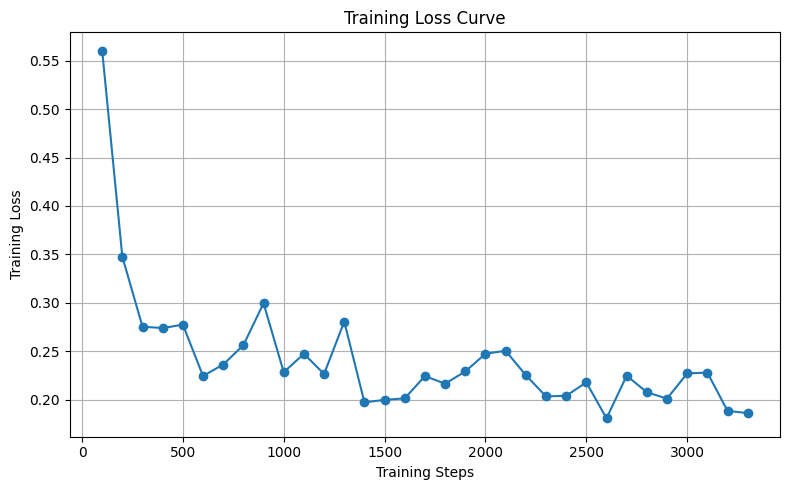

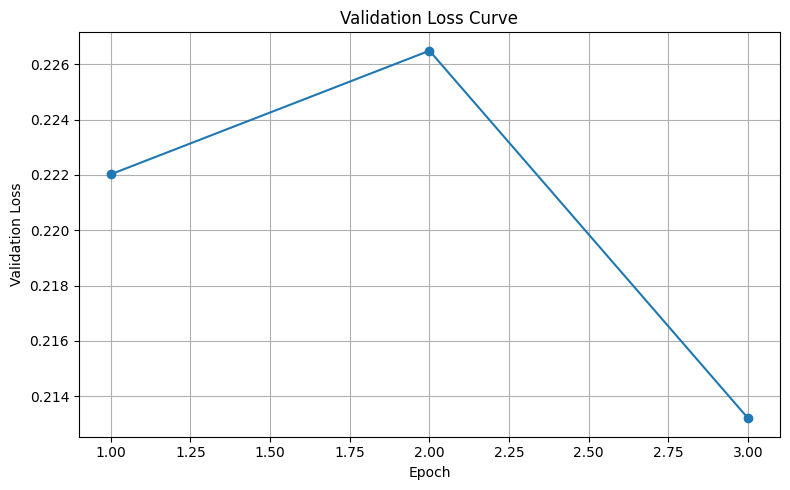

In [35]:
# Extract training history
history = trainer.state.log_history

train_steps = []
train_loss = []

eval_epochs = []
eval_loss = []

for record in history:

    if "loss" in record and "step" in record:
        train_steps.append(record["step"])
        train_loss.append(record["loss"])

    if "eval_loss" in record and "epoch" in record:
        eval_epochs.append(record["epoch"])
        eval_loss.append(record["eval_loss"])


# Training Loss
plt.figure(figsize=(8, 5))

plt.plot(train_steps, train_loss, marker="o")

plt.title("Training Loss Curve")
plt.xlabel("Training Steps")
plt.ylabel("Training Loss")
plt.grid(True)
plt.tight_layout()
plt.show()


# Validation Loss
plt.figure(figsize=(8, 5))

plt.plot(eval_epochs, eval_loss, marker="o")

plt.title("Validation Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

In [36]:
#The model generates predictions for every test sample.
prediction_output = trainer.predict(
    test_dataset
)

predicted_labels = np.argmax(
    prediction_output.predictions,
    axis=1
)

actual_labels = y_test

In [37]:
#This gives detailed performance for each class
print(
    classification_report(
        actual_labels,
        predicted_labels,
        target_names=[
            "Legitimate",
            "Phishing"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Legitimate       0.92      0.96      0.94       616
    Phishing       0.95      0.90      0.92       490

    accuracy                           0.93      1106
   macro avg       0.93      0.93      0.93      1106
weighted avg       0.93      0.93      0.93      1106



In [38]:
#Calculate Final Metrics
accuracy = accuracy_score(
    actual_labels,
    predicted_labels
)

precision = precision_score(
    actual_labels,
    predicted_labels,
    zero_division=0
)

recall = recall_score(
    actual_labels,
    predicted_labels,
    zero_division=0
)

f1 = f1_score(
    actual_labels,
    predicted_labels,
    zero_division=0
)

print("Final Model 1 Performance")
print("=========================")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Final Model 1 Performance
Accuracy : 0.9322
Precision: 0.9462
Recall   : 0.8980
F1 Score : 0.9215


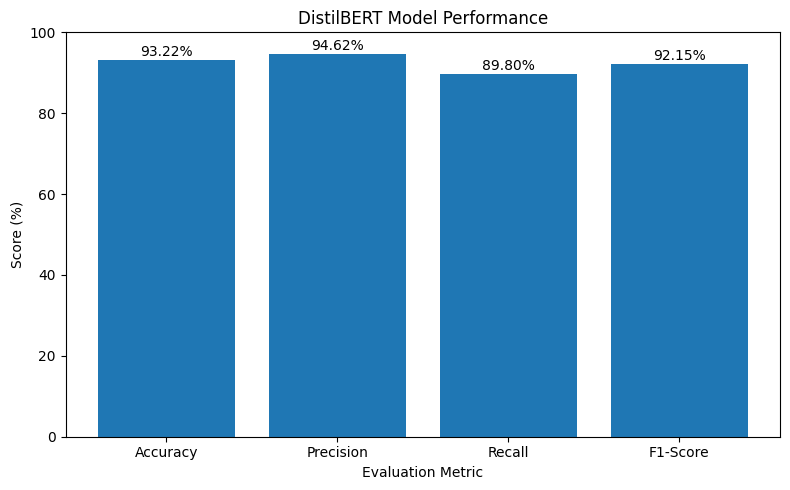

In [39]:
# Performance Metrics Graph

metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
}

plt.figure(figsize=(8, 5))

plt.bar(
    metrics.keys(),
    [value * 100 for value in metrics.values()]
)

plt.title("DistilBERT Model Performance")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score (%)")
plt.ylim(0, 100)

for i, value in enumerate(metrics.values()):
    plt.text(
        i,
        value * 100 + 1,
        f"{value * 100:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

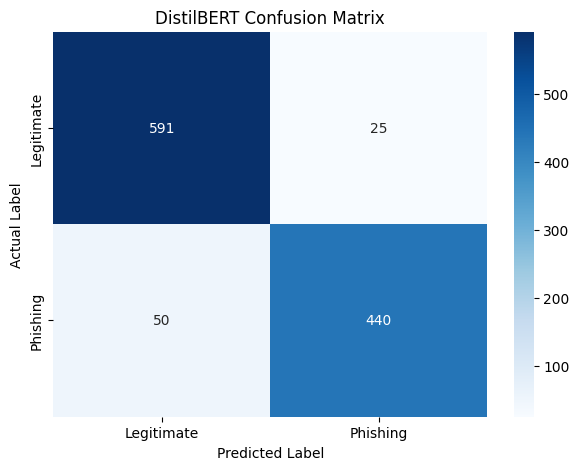

In [40]:
'''
For phishing detection:

TP → Correctly detected phishing
TN → Correctly detected legitimate
FP → Legitimate incorrectly classified as phishing
FN → Phishing incorrectly classified as legitimate

FN is especially important because it represents phishing websites that the model failed to detect.
'''

cm = confusion_matrix(
    actual_labels,
    predicted_labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Legitimate",
        "Phishing"
    ],
    yticklabels=[
        "Legitimate",
        "Phishing"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("DistilBERT Confusion Matrix")

plt.show()

Predictions generated successfully.
Number of predictions: 1106
Error Metrics
False Positive Rate : 0.0406 (4.06%)
False Negative Rate : 0.1020 (10.20%)


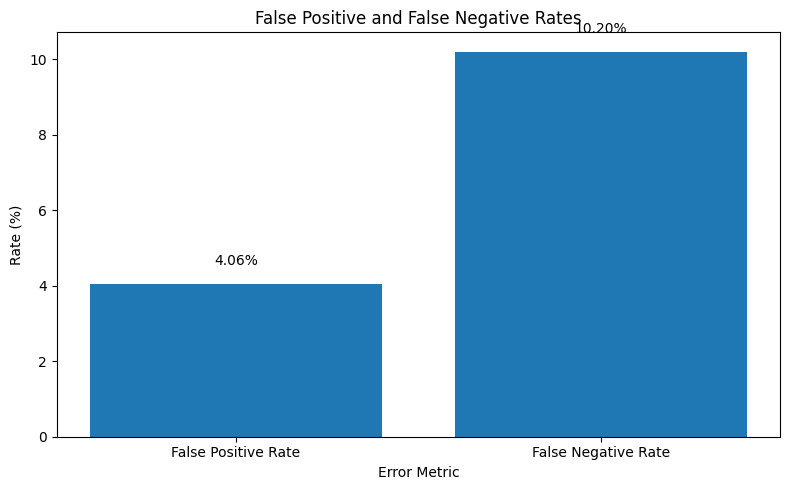

In [41]:
# ==========================================
# GENERATE TEST PREDICTIONS
# ==========================================

import numpy as np

# Generate predictions using the trained DistilBERT model
test_output = trainer.predict(test_dataset)

# Convert model outputs into predicted class labels
predictions = np.argmax(test_output.predictions, axis=1)

print("Predictions generated successfully.")
print("Number of predictions:", len(predictions))
# ==========================================
# FALSE POSITIVE RATE AND FALSE NEGATIVE RATE
# ==========================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, predictions)

# Extract TN, FP, FN, TP
tn, fp, fn, tp = cm.ravel()

# Calculate FPR and FNR
fpr = fp / (fp + tn)
fnr = fn / (fn + tp)

# Display values
print("Error Metrics")
print("=" * 35)
print(f"False Positive Rate : {fpr:.4f} ({fpr * 100:.2f}%)")
print(f"False Negative Rate : {fnr:.4f} ({fnr * 100:.2f}%)")


# ==========================================
# GRAPH
# ==========================================

error_metrics = {
    "False Positive Rate": fpr * 100,
    "False Negative Rate": fnr * 100
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    error_metrics.keys(),
    error_metrics.values()
)

plt.title("False Positive and False Negative Rates")
plt.xlabel("Error Metric")
plt.ylabel("Rate (%)")

for bar, value in zip(bars, error_metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [42]:
#This saves the trained model so that we don't have to retrain it every time.

#The folder will contain the trained DistilBERT model.

model.save_pretrained(
    "./saved_model"
)

tokenizer.save_pretrained(
    "./saved_model"
)

print("Model and tokenizer saved successfully.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved successfully.


In [43]:
import os

print(os.listdir("./saved_model"))

['tokenizer_config.json', 'tokenizer.json', 'config.json', 'model.safetensors']
